# CivicVision Lite: Pothole Detection and Inspection-Triage Support

**Deep Learning Lab Mini-Project**  
**Model:** YOLOv8n transfer learning · **Dataset:** Annotated Water-Filled and Dry Potholes Dataset · **Framework:** PyTorch + Ultralytics

## Abstract
CivicVision Lite detects potholes in road photographs and returns bounding boxes, confidence scores, and a transparent **experimental inspection-priority index**. A compact pretrained object detector is fine-tuned on an annotated pothole dataset. The notebook also evaluates the detector, measures inference time, visualizes examples, and offers an image-upload demo.

## Problem statement
Manual road inspection is difficult to scale. CivicVision Lite explores whether a lightweight object detector can help flag visible potholes for human review.

## Objectives
1. Prepare annotated road images for object detection.
2. Fine-tune a lightweight pretrained detector on a reproducible subset.
3. Evaluate precision, recall, mAP@0.50 and mAP@0.50:0.95.
4. Visualize ground-truth annotations, predictions, and possible errors.
5. Provide an image-upload demo with a transparent, rule-based triage index.
6. Package a small annotated dataset subset for a GitHub-friendly demonstration.

## Important limitations
- This is an educational prototype, **not** a certified road-safety or engineering assessment system.
- The priority index is a demonstration heuristic, not a validated pavement-severity measure.
- This dataset is used for **one object class: pothole**. It includes variation such as dry and water-filled potholes, but those conditions are not treated as separate classes in this notebook.
- Training uses a limited subset, so measured performance should not be generalized to all roads, countries, weather conditions, or cameras.

## Notebook workflow
Environment check → prepare/download source dataset → parse YOLO/VOC annotations → create portable subset → inspect labels → train → evaluate → benchmark latency → image-upload demo → conclusions.


## 1. Install / verify dependencies

Run this cell once in the notebook environment. It installs Ultralytics but does not reinstall PyTorch, which avoids unnecessarily replacing a working CUDA build.

In [4]:
%pip install -q ultralytics ipywidgets pyyaml tqdm requests

Note: you may need to restart the kernel to use updated packages.


## 2. Imports, reproducibility, and device configuration

In [5]:
import os
import sys
import time
import json
import random
import shutil
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import requests
import yaml
import torch
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Resolve the project folder whether Jupyter was started from D:\ or mini_project\.
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name.lower() != "mini_project" and (CURRENT_DIR / "mini_project").is_dir():
    PROJECT_DIR = CURRENT_DIR / "mini_project"
else:
    PROJECT_DIR = CURRENT_DIR

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
EXTRACT_DIR = RAW_DIR / "Potholes_extracted"
YOLO_DATA_DIR = DATA_DIR / "yolo_pothole_subset"
MINI_DATASET_ZIP = PROJECT_DIR / "civicvision_pothole_mini.zip"
MINI_DATASET_DIR = DATA_DIR / "civicvision_pothole_mini"
PREBUILT_DATASET = False
OUTPUT_DIR = PROJECT_DIR / "outputs"
RUNS_DIR = OUTPUT_DIR / "training_runs"

for folder in [RAW_DIR, OUTPUT_DIR, RUNS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):", round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2))
    torch.backends.cudnn.benchmark = True
else:
    print("Using CPU. Training will be slower; verify your CUDA-enabled PyTorch install if you expected the RTX 2050.")
print("Project folder:", PROJECT_DIR)

# Reproducible, laptop-friendly starting settings.
MAX_IMAGES = 300         # Small subset from the 713-image source dataset.
PORTABLE_TRAIN_IMAGES = 120
PORTABLE_VAL_IMAGES = 30
MAX_PORTABLE_ZIP_MB = 20  # Keep one dataset ZIP below GitHub's 25 MiB browser-upload limit.
TRAIN_FRACTION = 0.80
IMAGE_SIZE = 416        # Reduced from 640 to reduce VRAM use.
BATCH_SIZE = 4          # If CUDA runs out of memory, reduce to 2.
EPOCHS = 8              # Increase only after a successful first run.
CONFIDENCE_THRESHOLD = 0.25


Python: 3.14.0
PyTorch: 2.14.0+cpu
CUDA available: False
Using CPU. Training will be slower; verify your CUDA-enabled PyTorch install if you expected the RTX 2050.
Project folder: D:\SEM-V\Deep Learning\DL-Lab\mini_project


## 3. Dataset source and GitHub-friendly workflow

We use the **[Annotated Water-Filled and Dry Potholes Dataset on Mendeley Data](https://data.mendeley.com/datasets/tp95cdvgm8/1)**. The dataset page describes **713 photographs and 1,152 manually annotated potholes**. It includes both YOLO text labels and Pascal VOC XML annotations, and the record lists a **Creative Commons Attribution 4.0 (CC BY 4.0)** license. Please retain attribution if you redistribute a subset. Sources: [dataset record](https://data.mendeley.com/datasets/tp95cdvgm8/1) and [associated data article](https://doi.org/10.1016/j.dib.2023.109206).

### One-time source download
1. Open the Mendeley Data page above.
2. Download **`Potholes.zip`** (images and annotations). Avoid downloading the two optional dashcam videos for this notebook.
3. Place it at `mini_project/data/raw/Potholes.zip`.
4. Run this notebook from top to bottom.

The source archive is used only to generate a smaller working sample. The notebook resizes and compresses up to **120 training + 30 validation images**, keeping normalized bounding-box labels aligned. It automatically reduces the number of images further if necessary to target a ZIP under **20 MiB**.

### What belongs in GitHub?
Commit `project.ipynb`, this source-attribution note, and the generated `civicvision_pothole_mini.zip` only after verifying that its size is below 20 MiB. Do **not** commit the full source archive, extracted working data, model weights, or training outputs. GitHub browser uploads are limited to 25 MiB per file, while regular Git pushes block files over 100 MiB ([GitHub documentation](https://docs.github.com/en/repositories/working-with-files/managing-large-files/about-large-files-on-github)).

If `civicvision_pothole_mini.zip` is already present beside the notebook, the notebook uses it directly and skips the source archive step on future runs.


In [6]:
# Prefer the compact, GitHub-friendly dataset if it is already present.
# Otherwise, place Potholes.zip at data/raw/Potholes.zip after downloading it from Mendeley Data.
MENDELEY_DATASET_PAGE = "https://data.mendeley.com/datasets/tp95cdvgm8/1"
DATASET_ARTICLE_DOI = "10.1016/j.dib.2023.109206"
ZIP_PATH = RAW_DIR / "Potholes.zip"


def extract_zip_safely(archive_path: Path, destination: Path) -> None:
    """Extract an archive once; remove incomplete extracts before retrying."""
    marker = destination / ".extraction_complete"
    if marker.exists():
        return
    if destination.exists():
        shutil.rmtree(destination)
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(destination)
    marker.write_text("complete", encoding="utf-8")


if MINI_DATASET_ZIP.exists() and zipfile.is_zipfile(MINI_DATASET_ZIP):
    print("Found compact dataset archive:", MINI_DATASET_ZIP)
    if MINI_DATASET_DIR.exists():
        shutil.rmtree(MINI_DATASET_DIR)
    extract_zip_safely(MINI_DATASET_ZIP, MINI_DATASET_DIR)
    YOLO_DATA_DIR = MINI_DATASET_DIR
    DATA_YAML = YOLO_DATA_DIR / "data.yaml"
    if not DATA_YAML.exists():
        raise FileNotFoundError(
            f"Compact dataset archive is missing data.yaml: {MINI_DATASET_ZIP}. "
            "Recreate it from the source dataset using this notebook."
        )
    mini_yaml = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
    mini_yaml["path"] = str(YOLO_DATA_DIR.resolve()).replace("\\", "/")
    DATA_YAML.write_text(yaml.safe_dump(mini_yaml, sort_keys=False, allow_unicode=True), encoding="utf-8")
    DATASET_URL = "Local civicvision_pothole_mini.zip"
    PREBUILT_DATASET = True
    print("Using the portable dataset; no source download is needed.")
else:
    PREBUILT_DATASET = False
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            "Pothole dataset archive not found.\n\n"
            "1. Open: " + MENDELEY_DATASET_PAGE + "\n"
            "2. Download the file named 'Potholes.zip' (images + annotations; skip optional videos).\n"
            "3. Save it as: " + str(ZIP_PATH) + "\n"
            "4. Run this cell again.\n\n"
            "After the first successful run, the notebook creates civicvision_pothole_mini.zip "
            "so you can commit the small subset to GitHub."
        )
    if not zipfile.is_zipfile(ZIP_PATH):
        raise RuntimeError(f"The file at {ZIP_PATH} is not a valid ZIP archive. Re-download Potholes.zip.")
    print(f"Using source archive: {ZIP_PATH} ({ZIP_PATH.stat().st_size / (1024**2):.1f} MiB)")
    if not (EXTRACT_DIR / ".extraction_complete").exists():
        print("Extracting the image/annotation archive...")
        extract_zip_safely(ZIP_PATH, EXTRACT_DIR)
    print("Dataset extraction ready:", EXTRACT_DIR)
    DATASET_URL = MENDELEY_DATASET_PAGE


Using source archive: D:\SEM-V\Deep Learning\DL-Lab\mini_project\data\raw\Potholes.zip (554.3 MiB)
Extracting the image/annotation archive...
Dataset extraction ready: D:\SEM-V\Deep Learning\DL-Lab\mini_project\data\raw\Potholes_extracted


## 4. Parse YOLO/VOC annotations and create a reproducible subset

The source dataset provides YOLO text annotations and Pascal VOC XML annotations. The notebook uses the normalized YOLO coordinates when available and falls back to VOC boxes when required. For this experiment, all annotated potholes map to one class: **Pothole (class 0)**. Images are split into training and validation sets before model fitting.


In [7]:
CLASS_NAMES = ["Pothole"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def parse_yolo_annotation(label_path: Path):
    """Read YOLO normalized boxes; map all source class ids to the single pothole class."""
    if not label_path.is_file():
        return None
    labels = []
    try:
        lines = label_path.read_text(encoding="utf-8", errors="ignore").splitlines()
    except OSError:
        return None
    for line in lines:
        parts = line.strip().split()
        if not parts:
            continue
        if len(parts) < 5:
            continue
        try:
            _, xc, yc, bw, bh = map(float, parts[:5])
        except ValueError:
            continue
        # YOLO uses normalized center-x, center-y, width, height.
        if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            continue
        labels.append((0, xc, yc, bw, bh))
    # An existing empty label file is a valid negative sample; None means no usable file was found.
    return labels


def parse_voc_annotation(xml_path: Path):
    """Read Pascal VOC boxes and normalize them for YOLO; all objects map to Pothole."""
    try:
        root = ET.parse(xml_path).getroot()
    except (ET.ParseError, OSError):
        return None
    size_node = root.find("size")
    width = int(size_node.findtext("width", "0")) if size_node is not None else 0
    height = int(size_node.findtext("height", "0")) if size_node is not None else 0
    if width <= 0 or height <= 0:
        return None
    labels = []
    for obj in root.findall("object"):
        box = obj.find("bndbox")
        if box is None:
            continue
        try:
            xmin, ymin, xmax, ymax = [float(box.findtext(k, "0")) for k in ("xmin", "ymin", "xmax", "ymax")]
        except ValueError:
            continue
        xmin = max(0.0, min(xmin, width - 1.0))
        ymin = max(0.0, min(ymin, height - 1.0))
        xmax = max(0.0, min(xmax, width - 1.0))
        ymax = max(0.0, min(ymax, height - 1.0))
        if xmax <= xmin or ymax <= ymin:
            continue
        labels.append((0, ((xmin + xmax) / 2) / width, ((ymin + ymax) / 2) / height,
                       (xmax - xmin) / width, (ymax - ymin) / height))
    return labels


def count_yolo_boxes(split_name):
    counts = Counter()
    label_dir = YOLO_DATA_DIR / "labels" / split_name
    for label_path in label_dir.glob("*.txt"):
        for line in label_path.read_text(encoding="utf-8", errors="ignore").splitlines():
            parts = line.split()
            if len(parts) == 5:
                try:
                    counts[int(float(parts[0]))] += 1
                except ValueError:
                    pass
    return counts


if PREBUILT_DATASET:
    train_records = list((YOLO_DATA_DIR / "images" / "train").glob("*"))
    val_records = list((YOLO_DATA_DIR / "images" / "val").glob("*"))
    records = train_records + val_records
    train_image_count = len(train_records)
    val_image_count = len(val_records)
    train_box_counts = count_yolo_boxes("train")
    val_box_counts = count_yolo_boxes("val")
    print("Using prebuilt portable dataset; annotation conversion skipped.")
else:
    print("Indexing images and annotations...")
    image_paths = [p for p in EXTRACT_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    txt_paths = [p for p in EXTRACT_DIR.rglob("*.txt") if p.is_file()]
    xml_paths = [p for p in EXTRACT_DIR.rglob("*.xml") if p.is_file()]

    txt_by_stem = {}
    for label_path in txt_paths:
        txt_by_stem.setdefault(label_path.stem.lower(), []).append(label_path)
    xml_by_stem = {}
    for xml_path in xml_paths:
        xml_by_stem.setdefault(xml_path.stem.lower(), []).append(xml_path)

    records = []
    for image_path in tqdm(image_paths, desc="Matching images to labels"):
        labels = None
        matching_txts = txt_by_stem.get(image_path.stem.lower(), [])
        for label_path in matching_txts:
            parsed = parse_yolo_annotation(label_path)
            if parsed is not None:
                labels = parsed
                break
        if labels is None:
            matching_xmls = xml_by_stem.get(image_path.stem.lower(), [])
            for xml_path in matching_xmls:
                parsed = parse_voc_annotation(xml_path)
                if parsed is not None:
                    labels = parsed
                    break
        if labels is not None:
            records.append({"image": image_path, "labels": labels})

    if len(records) < 20:
        raise RuntimeError(
            f"Only {len(records)} image/annotation pairs were found. "
            "Check whether Potholes.zip was extracted correctly and contains matching image and TXT/XML files."
        )

    rng = random.Random(SEED)
    rng.shuffle(records)
    records = records[:min(MAX_IMAGES, len(records))] if MAX_IMAGES is not None else records
    split_index = max(1, int(len(records) * TRAIN_FRACTION))
    train_records, val_records = records[:split_index], records[split_index:]
    if not val_records:
        raise RuntimeError("Not enough annotated images for a validation split; increase MAX_IMAGES.")

    if YOLO_DATA_DIR.exists():
        shutil.rmtree(YOLO_DATA_DIR)
    for split in ("train", "val"):
        (YOLO_DATA_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
        (YOLO_DATA_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

    def write_yolo_subset(records_for_split, split_name):
        box_counts = Counter()
        image_count = 0
        for record in tqdm(records_for_split, desc=f"Preparing {split_name}"):
            image_path = record["image"]
            target_name = f"{split_name}_{image_count:06d}.jpg"
            target_image = YOLO_DATA_DIR / "images" / split_name / target_name
            target_label = YOLO_DATA_DIR / "labels" / split_name / f"{Path(target_name).stem}.txt"
            # Resize/re-encode working images to reduce disk use; normalized boxes remain valid.
            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img.thumbnail((640, 640), Image.Resampling.LANCZOS)
                img.save(target_image, format="JPEG", quality=86, optimize=True)
            lines = []
            for cls_id, xc, yc, bw, bh in record["labels"]:
                lines.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
                box_counts[cls_id] += 1
            target_label.write_text("\n".join(lines), encoding="utf-8")
            image_count += 1
        return image_count, box_counts

    train_image_count, train_box_counts = write_yolo_subset(train_records, "train")
    val_image_count, val_box_counts = write_yolo_subset(val_records, "val")
    DATA_YAML = YOLO_DATA_DIR / "data.yaml"
    data_config = {
        "path": str(YOLO_DATA_DIR.resolve()).replace("\\", "/"),
        "train": "images/train",
        "val": "images/val",
        "names": {index: name for index, name in enumerate(CLASS_NAMES)},
    }
    DATA_YAML.write_text(yaml.safe_dump(data_config, sort_keys=False, allow_unicode=True), encoding="utf-8")

class_summary = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Train boxes": [train_box_counts.get(i, 0) for i in range(len(CLASS_NAMES))],
    "Validation boxes": [val_box_counts.get(i, 0) for i in range(len(CLASS_NAMES))],
})
print(f"Selected images: {len(records):,}")
print(f"Training images: {train_image_count:,} | Validation images: {val_image_count:,}")
if train_box_counts.get(0, 0) == 0:
    print("WARNING: no training pothole boxes were found. Inspect the labels before training.")
print("YOLO dataset YAML:", DATA_YAML)
display(class_summary)


Indexing images and annotations...


Matching images to labels:   0%|          | 0/713 [00:00<?, ?it/s]

Preparing train:   0%|          | 0/240 [00:00<?, ?it/s]

Preparing val:   0%|          | 0/60 [00:00<?, ?it/s]

Selected images: 300
Training images: 240 | Validation images: 60
YOLO dataset YAML: D:\SEM-V\Deep Learning\DL-Lab\mini_project\data\yolo_pothole_subset\data.yaml


,Class,Train boxes,Validation boxes
0,Pothole,361,118


## 4.1 Export a compact dataset for GitHub

When the full source archive was used, this cell creates `civicvision_pothole_mini.zip` beside `project.ipynb`. It contains up to 80 training and 20 validation images, resized to at most 512 px and JPEG-compressed. Labels are kept in normalized YOLO format, so box coordinates remain valid after proportional resizing. The exporter reduces the sample further if needed to stay below 20 MiB. Commit this ZIP only after preserving dataset attribution and checking applicable license terms.

On subsequent runs, the notebook detects this ZIP in Section 3 and uses it directly, avoiding a new full-dataset download.


In [8]:
# Create one small, portable pothole dataset archive that can be committed to GitHub.
# The archive is generated from the selected pothole-image subset, not from the full source archive.
if MINI_DATASET_ZIP.exists() and PREBUILT_DATASET:
    print(f"Portable dataset already available: {MINI_DATASET_ZIP} ({MINI_DATASET_ZIP.stat().st_size / (1024**2):.2f} MiB)")
elif PREBUILT_DATASET:
    print("This run already uses a portable dataset. No re-export is necessary.")
else:
    def classes_for_image(image_path, split_name):
        label_path = YOLO_DATA_DIR / "labels" / split_name / f"{image_path.stem}.txt"
        found = set()
        if label_path.exists():
            for line in label_path.read_text(encoding="utf-8").splitlines():
                parts = line.split()
                if len(parts) == 5:
                    try:
                        found.add(int(parts[0]))
                    except ValueError:
                        pass
        return found

    def choose_diverse(files, target_count, split_name):
        """Greedy selection favors images containing underrepresented pothole class."""
        files = list(files)
        if len(files) <= target_count:
            return files
        presence = {p: classes_for_image(p, split_name) for p in files}
        global_counts = Counter(cls for labels in presence.values() for cls in labels)
        selected = []
        selected_counts = Counter()
        remaining = set(files)
        while remaining and len(selected) < target_count:
            def score(path):
                labels = presence[path]
                if not labels:
                    return 0.0
                return sum(1.0 / ((global_counts[c] ** 0.5) * (selected_counts[c] + 1)) for c in labels)
            best = max(remaining, key=score)
            selected.append(best)
            selected_counts.update(presence[best])
            remaining.remove(best)
        return selected

    train_images = sorted((YOLO_DATA_DIR / "images" / "train").glob("*"))
    val_images = sorted((YOLO_DATA_DIR / "images" / "val").glob("*"))
    train_target = min(PORTABLE_TRAIN_IMAGES, len(train_images))
    val_target = min(PORTABLE_VAL_IMAGES, len(val_images))
    portable_root = DATA_DIR / "portable_dataset_build"
    max_bytes = int(MAX_PORTABLE_ZIP_MB * 1024 * 1024)

    while True:
        if portable_root.exists():
            shutil.rmtree(portable_root)
        for split_name in ("train", "val"):
            (portable_root / "images" / split_name).mkdir(parents=True, exist_ok=True)
            (portable_root / "labels" / split_name).mkdir(parents=True, exist_ok=True)

        split_files = {
            "train": choose_diverse(train_images, train_target, "train"),
            "val": choose_diverse(val_images, val_target, "val"),
        }
        for split_name, files in split_files.items():
            for index, source_image in enumerate(tqdm(files, desc=f"Building portable {split_name}")):
                output_name = f"{split_name}_{index:04d}.jpg"
                output_image = portable_root / "images" / split_name / output_name
                source_label = YOLO_DATA_DIR / "labels" / split_name / f"{source_image.stem}.txt"
                output_label = portable_root / "labels" / split_name / f"{Path(output_name).stem}.txt"

                # Proportional resize preserves normalized bounding-box coordinates.
                with Image.open(source_image) as img:
                    img = img.convert("RGB")
                    img.thumbnail((512, 512), Image.Resampling.LANCZOS)
                    img.save(output_image, format="JPEG", quality=76, optimize=True)
                output_label.write_text(
                    source_label.read_text(encoding="utf-8") if source_label.exists() else "",
                    encoding="utf-8",
                )

        portable_yaml = {
            "path": ".",
            "train": "images/train",
            "val": "images/val",
            "names": {index: name for index, name in enumerate(CLASS_NAMES)},
        }
        (portable_root / "data.yaml").write_text(
            yaml.safe_dump(portable_yaml, sort_keys=False, allow_unicode=True), encoding="utf-8"
        )
        if MINI_DATASET_ZIP.exists():
            MINI_DATASET_ZIP.unlink()
        with zipfile.ZipFile(MINI_DATASET_ZIP, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
            for file_path in portable_root.rglob("*"):
                if file_path.is_file():
                    zf.write(file_path, file_path.relative_to(portable_root))

        zip_bytes = MINI_DATASET_ZIP.stat().st_size
        print(f"Portable dataset size: {zip_bytes / (1024**2):.2f} MiB")
        if zip_bytes <= max_bytes:
            break
        if train_target <= 20 and val_target <= 5:
            print("WARNING: ZIP remains above the size target; reduce image counts or JPEG quality manually.")
            break
        train_target = max(20, int(train_target * 0.8))
        val_target = max(5, int(val_target * 0.8))
        print(f"Reducing portable sample to {train_target} train + {val_target} validation images to meet the size target...")

    shutil.rmtree(portable_root, ignore_errors=True)
    print("Created:", MINI_DATASET_ZIP)
    print("Add this ZIP to GitHub with the notebook, not the full source archive.")

# Reproducibility: use exactly the compact dataset that will be stored in GitHub.
# This ensures the notebook's training/evaluation set matches future runs from the repo.
if not PREBUILT_DATASET and MINI_DATASET_ZIP.exists():
    if MINI_DATASET_DIR.exists():
        shutil.rmtree(MINI_DATASET_DIR)
    extract_zip_safely(MINI_DATASET_ZIP, MINI_DATASET_DIR)
    YOLO_DATA_DIR = MINI_DATASET_DIR
    DATA_YAML = YOLO_DATA_DIR / "data.yaml"
    portable_config = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
    portable_config["path"] = str(YOLO_DATA_DIR.resolve()).replace("\\", "/")
    DATA_YAML.write_text(yaml.safe_dump(portable_config, sort_keys=False, allow_unicode=True), encoding="utf-8")
    PREBUILT_DATASET = True
    train_records = list((YOLO_DATA_DIR / "images" / "train").glob("*"))
    val_records = list((YOLO_DATA_DIR / "images" / "val").glob("*"))
    records = train_records + val_records
    train_image_count = len(train_records)
    val_image_count = len(val_records)
    train_box_counts = count_yolo_boxes("train")
    val_box_counts = count_yolo_boxes("val")
    class_summary = pd.DataFrame({
        "Class": CLASS_NAMES,
        "Train boxes": [train_box_counts.get(i, 0) for i in range(len(CLASS_NAMES))],
        "Validation boxes": [val_box_counts.get(i, 0) for i in range(len(CLASS_NAMES))],
    })
    print("Training will use the same compact dataset archived for GitHub:")
    print(f"Images: {train_image_count} train + {val_image_count} validation")
    display(class_summary)


Building portable train:   0%|          | 0/120 [00:00<?, ?it/s]

Building portable val:   0%|          | 0/30 [00:00<?, ?it/s]

Portable dataset size: 5.71 MiB
Created: D:\SEM-V\Deep Learning\DL-Lab\mini_project\civicvision_pothole_mini.zip
Add this ZIP to GitHub with the notebook, not the full source archive.
Training will use the same compact dataset archived for GitHub:
Images: 120 train + 30 validation


,Class,Train boxes,Validation boxes
0,Pothole,187,69


## 5. Inspect the converted data

Check that images and their boxes look correct before spending time training. This is also a useful visual check for a lab viva.

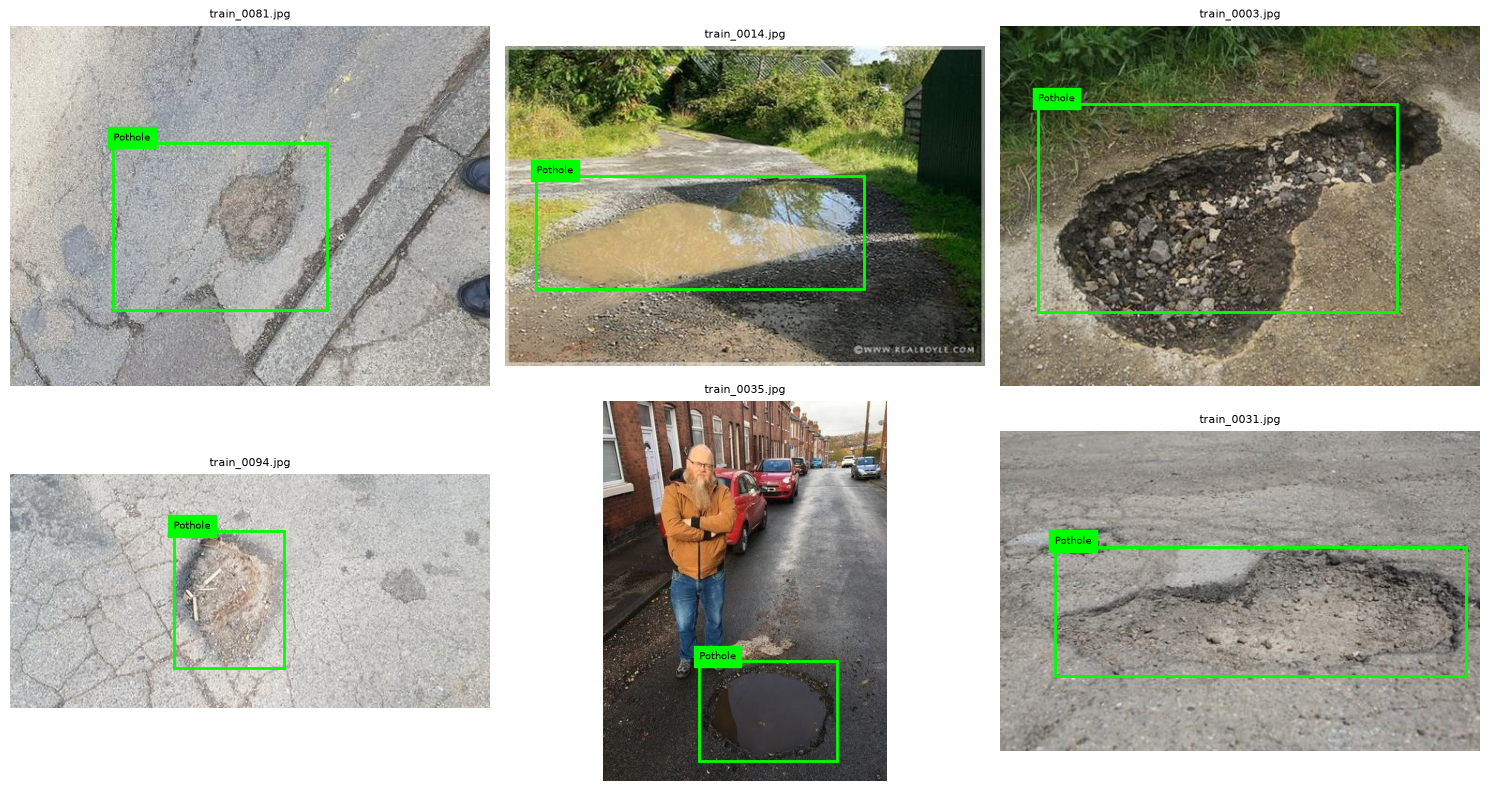

290

In [9]:
def show_ground_truth_examples(split="train", n=6):
    image_dir = YOLO_DATA_DIR / "images" / split
    label_dir = YOLO_DATA_DIR / "labels" / split
    image_files = list(image_dir.glob("*"))
    if not image_files:
        print("No images found in", image_dir)
        return

    rng_local = random.Random(SEED)
    examples = rng_local.sample(image_files, min(n, len(image_files)))
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.ravel()
    for ax, image_path in zip(axes, examples):
        image = Image.open(image_path).convert("RGB")
        width, height = image.size
        ax.imshow(image)
        label_path = label_dir / f"{image_path.stem}.txt"
        if label_path.exists():
            for line in label_path.read_text(encoding="utf-8").splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue
                cls_id, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])
                x0 = (xc - bw / 2) * width
                y0 = (yc - bh / 2) * height
                rect = plt.Rectangle((x0, y0), bw * width, bh * height,
                                     fill=False, linewidth=2, edgecolor="lime")
                ax.add_patch(rect)
                ax.text(x0, max(0, y0 - 3), CLASS_NAMES[cls_id], color="black",
                        fontsize=7, backgroundcolor="lime")
        ax.set_title(image_path.name, fontsize=8)
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_ground_truth_examples("train", n=6)

# Save dataset metadata for reproducibility.
metadata = {
    "dataset": "Annotated Water-Filled and Dry Potholes Dataset",
    "source_url": DATASET_URL,
    "seed": SEED,
    "max_images_setting": MAX_IMAGES,
    "selected_images": len(records),
    "train_images": train_image_count,
    "validation_images": val_image_count,
    "class_names": CLASS_NAMES,
}
(OUTPUT_DIR / "dataset_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

## 6. Train the model

We fine-tune a pretrained **YOLOv8n** detector. This is a transfer-learning experiment: the model begins with general visual features instead of training every parameter from random initialization. Settings are conservative for a laptop GPU (416-pixel input, batch size 4, 8 epochs, no RAM caching).

In [ ]:
BASE_MODEL = "yolov8n.pt"
model = YOLO(BASE_MODEL)

train_start = time.perf_counter()
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=0,                 # Safer on Windows/Jupyter
    project=str(RUNS_DIR),
    name="civicvision_yolov8n",
    exist_ok=True,
    pretrained=True,
    patience=4,
    amp=True,
    cache=False,
    plots=True,
    seed=SEED,
    deterministic=True,
    close_mosaic=2,
    verbose=True,
)
training_seconds = time.perf_counter() - train_start

run_dir = Path(model.trainer.save_dir)
best_weights = run_dir / "weights" / "best.pt"
last_weights = run_dir / "weights" / "last.pt"
if not best_weights.exists():
    candidate = last_weights if last_weights.exists() else None
    if candidate is None:
        raise FileNotFoundError(f"Could not find trained weights under {run_dir / 'weights'}")
    best_weights = candidate

SAVED_BEST_MODEL = OUTPUT_DIR / "civicvision_yolov8n_best.pt"
shutil.copy2(best_weights, SAVED_BEST_MODEL)
print(f"Training time: {training_seconds / 60:.1f} minutes")
print("Training run:", run_dir)
print("Saved model:", SAVED_BEST_MODEL)

New https://pypi.org/project/ultralytics/8.4.175 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.162  Python-3.14.0 torch-2.14.0+cpu CPU (AMD Ryzen 5 5600H with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\SEM-V\Deep Learning\DL-Lab\mini_project\data\civicvision_pothole_mini\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01,

## 7. Evaluate on the held-out validation split

The validation split is kept separate from training. The metrics below are calculated by the detector evaluation pipeline; values depend on the selected subset, seed, hardware, and training duration.

In [ ]:
best_model = YOLO(str(SAVED_BEST_MODEL))
validation_start = time.perf_counter()
val_results = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=0,
    plots=True,
    project=str(RUNS_DIR),
    name="civicvision_validation",
    exist_ok=True,
    verbose=True,
)
validation_seconds = time.perf_counter() - validation_start

box_metrics = getattr(val_results, "box", None)
if box_metrics is not None:
    evaluation_summary = {
        "Precision": float(box_metrics.mp),
        "Recall": float(box_metrics.mr),
        "mAP@0.50": float(box_metrics.map50),
        "mAP@0.50:0.95": float(box_metrics.map),
        "Training time (minutes)": training_seconds / 60,
        "Validation time (seconds)": validation_seconds,
    }
    display(pd.DataFrame([evaluation_summary]).T.rename(columns={0: "Value"}).round(4))
    (OUTPUT_DIR / "evaluation_metrics.json").write_text(json.dumps(evaluation_summary, indent=2), encoding="utf-8")
else:
    print("Validation ran, but the expected bounding-box metrics were not found. Inspect val_results above.")

## 8. Plot training curves

Ultralytics writes a `results.csv` file in the training run folder. We inspect its available columns instead of assuming every library version uses an identical column schema.

In [ ]:
results_csv = run_dir / "results.csv"
if results_csv.exists():
    history = pd.read_csv(results_csv)
    history.columns = [column.strip() for column in history.columns]
    print("Available training history columns:", list(history.columns))

    loss_columns = [column for column in history.columns if "loss" in column.lower() and "gpu" not in column.lower()]
    metric_columns = [column for column in history.columns if any(term in column.lower() for term in ["precision", "recall", "map50", "map50-95"])]

    if loss_columns:
        plt.figure(figsize=(11, 5))
        for column in loss_columns:
            plt.plot(history.index + 1, history[column], label=column)
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("CivicVision Training / Validation Losses")
        plt.grid(alpha=0.3)
        plt.legend(fontsize=8, ncol=2)
        plt.tight_layout()
        plt.show()

    if metric_columns:
        plt.figure(figsize=(10, 5))
        for column in metric_columns:
            plt.plot(history.index + 1, history[column], label=column)
        plt.xlabel("Epoch")
        plt.ylabel("Metric")
        plt.title("Validation Detection Metrics During Training")
        plt.grid(alpha=0.3)
        plt.legend(fontsize=8)
        plt.tight_layout()
        plt.show()
else:
    print("Training history CSV not found at", results_csv)

## 9. Inference-speed benchmark

This is a simple per-image latency check on a small sample. Results include a small amount of per-call overhead, so treat them as a rough local benchmark rather than a standardized hardware comparison.

In [ ]:
val_image_dir = YOLO_DATA_DIR / "images" / "val"
benchmark_images = list(val_image_dir.glob("*"))[:20]
if benchmark_images:
    # Warm-up helps reduce first-call initialization effects.
    for image_path in benchmark_images[:min(3, len(benchmark_images))]:
        _ = best_model.predict(source=str(image_path), imgsz=IMAGE_SIZE, conf=CONFIDENCE_THRESHOLD,
                               device=DEVICE, verbose=False, save=False)
    timings = []
    for image_path in benchmark_images:
        start = time.perf_counter()
        _ = best_model.predict(source=str(image_path), imgsz=IMAGE_SIZE, conf=CONFIDENCE_THRESHOLD,
                               device=DEVICE, verbose=False, save=False)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        timings.append(time.perf_counter() - start)
    benchmark_summary = {
        "Images measured": len(timings),
        "Median latency (ms/image)": float(np.median(timings) * 1000),
        "Mean latency (ms/image)": float(np.mean(timings) * 1000),
        "Approx. images/second": float(1 / np.mean(timings)) if np.mean(timings) > 0 else None,
        "Device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    }
    display(pd.DataFrame([benchmark_summary]).T.rename(columns={0: "Value"}))
    (OUTPUT_DIR / "inference_benchmark.json").write_text(json.dumps(benchmark_summary, indent=2), encoding="utf-8")
else:
    print("No validation images found for the speed test.")

## 10. Inspect a validation prediction

The model writes an annotated pothole image to `outputs/predictions/`. Prediction confidence is not the same thing as damage severity.

In [ ]:
PREDICTION_DIR = OUTPUT_DIR / "predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)


def predict_image(image_path, conf=CONFIDENCE_THRESHOLD, save=True, display_image=True):
    """Detect potholes, visualize boxes, and return a transparent demonstration-only inspection-priority index."""
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    result = best_model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=conf,
        device=DEVICE,
        verbose=False,
        save=False,
    )[0]

    detections = []
    if result.boxes is not None and len(result.boxes) > 0:
        coordinates = result.boxes.xyxy.cpu().numpy()
        class_ids = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()
        for xyxy, class_id, confidence in zip(coordinates, class_ids, confidences):
            detections.append({
                "class_id": int(class_id),
                "damage_type": CLASS_NAMES[int(class_id)],
                "confidence": float(confidence),
                "x1": float(xyxy[0]), "y1": float(xyxy[1]),
                "x2": float(xyxy[2]), "y2": float(xyxy[3]),
            })

    # Demonstration-only heuristic: aggregate detector confidence, capped at 100.
    # It is not a physical pothole-severity estimate and is not engineering validated.
    priority_index = min(100.0, 100.0 * sum(item["confidence"] for item in detections))
    if not detections:
        priority_label = "No confident pothole detected — manual review may still be needed"
    elif priority_index < 25:
        priority_label = "Lower experimental index — review as part of routine inspection"
    elif priority_index < 60:
        priority_label = "Moderate experimental index — inspection recommended"
    else:
        priority_label = "Higher experimental index — prioritize human review"

    # Ultralytics plot output is BGR; reverse channels for Matplotlib/PIL.
    annotated_rgb = result.plot()[..., ::-1]
    save_path = PREDICTION_DIR / f"{image_path.stem}_civicvision.jpg"
    if save:
        Image.fromarray(annotated_rgb).save(save_path, quality=92)

    print("Image:", image_path.name)
    print("Detected supported objects:", len(detections))
    print(f"Experimental inspection-priority index: {priority_index:.1f}/100")
    print("Triage suggestion:", priority_label)
    print("Reminder: this heuristic is unvalidated and must not replace professional inspection.")

    if detections:
        display(pd.DataFrame(detections).drop(columns=["class_id"]).round(3))
    else:
        print("No predictions above the current confidence threshold.")

    if display_image:
        plt.figure(figsize=(12, 8))
        plt.imshow(annotated_rgb)
        plt.axis("off")
        plt.title(f"CivicVision: {image_path.name}")
        plt.show()

    if save:
        print("Annotated image saved to:", save_path)
    return {
        "image": str(image_path),
        "detections": detections,
        "priority_index_experimental": round(priority_index, 2),
        "triage_suggestion": priority_label,
        "annotated_image": str(save_path) if save else None,
    }

# Try one held-out validation image automatically as an example.
if benchmark_images:
    example_report = predict_image(benchmark_images[0])
    (OUTPUT_DIR / "example_prediction_report.json").write_text(json.dumps(example_report, indent=2), encoding="utf-8")

## 11. Upload and analyze your own road image

In a local Jupyter Notebook with ipywidgets enabled, use the upload control below. If the control does not render in your Jupyter setup, call `predict_image(r"D:\path\to\road_photo.jpg")` with an image path instead.

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Choose road image")
    analyze_button = widgets.Button(description="Analyze with CivicVision Lite", button_style="primary", icon="search")
    upload_output = widgets.Output()

    def _analyze_uploaded_image(_):
        with upload_output:
            clear_output(wait=True)
            uploaded_value = uploader.value
            if not uploaded_value:
                print("Choose an image first.")
                return
            # ipywidgets 7 returns a dict keyed by filename; ipywidgets 8 returns a tuple of file dictionaries.
            if isinstance(uploaded_value, dict):
                if "content" in uploaded_value:
                    item = uploaded_value
                else:
                    item = next(iter(uploaded_value.values()))
            else:
                item = uploaded_value[0]
            filename = Path(item.get("name", "uploaded_road_image.jpg")).name
            suffix = Path(filename).suffix.lower()
            if suffix not in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}:
                filename = "uploaded_road_image.jpg"
            uploaded_path = OUTPUT_DIR / filename
            uploaded_path.write_bytes(bytes(item["content"]))
            predict_image(uploaded_path)

    analyze_button.on_click(_analyze_uploaded_image)
    display(widgets.VBox([
        widgets.HTML("<b>Upload a road photograph</b><br>Use a clear image showing the road surface."),
        uploader,
        analyze_button,
        upload_output,
    ]))
except Exception as widget_error:
    print("Upload widget is not available in this environment:", widget_error)
    print(r'Use: predict_image(r"D:\\path\\to\\road_photo.jpg")')

## 12. Save a project summary and conclusions

In [ ]:
project_summary = {
    "project": "CivicVision Lite — Pothole Detection and Inspection-Triage Support",
    "dataset": "Annotated Water-Filled and Dry Potholes Dataset (compact subset)",
    "model": "YOLOv8n pretrained weights fine-tuned on the selected subset",
    "selected_images": len(records),
    "train_images": train_image_count,
    "validation_images": val_image_count,
    "epochs_requested": EPOCHS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "best_weights": str(SAVED_BEST_MODEL),
    "training_minutes": round(training_seconds / 60, 2),
    "priority_index_note": "Rule-based educational heuristic only; not engineering-validated.",
}
if "evaluation_summary" in globals():
    project_summary["validation_metrics"] = evaluation_summary
if "benchmark_summary" in globals():
    project_summary["inference_benchmark"] = benchmark_summary

(OUTPUT_DIR / "project_summary.json").write_text(json.dumps(project_summary, indent=2), encoding="utf-8")
print(json.dumps(project_summary, indent=2))

## Final conclusion (complete after training)

CivicVision Lite demonstrates a full single-class object-detection workflow: annotated-data preparation, transfer learning, validation, latency measurement, visual error inspection, and image-level inference. Fill in the measured validation results from `outputs/evaluation_metrics.json` in your lab report.

### Limitations and future improvements
- The current model detects potholes only; cracks and other road-damage categories are outside this version's scope.
- Training and validation use a small subset, so metrics have substantial sampling uncertainty. Do not present them as benchmark-quality results.
- Evaluate on a larger held-out test set and collect images from roads/cameras not present in training to check generalization.
- Add independent normal-road images and inspect false positives before using this system for real inspection workflows.
- The experimental priority index is based on detector confidence and count only; it is **not** an estimate of physical severity, risk, or repair cost.

### Dataset attribution
Dib, J., Sirlantzis, K., & Howells, G. (2023). *An annotated water-filled, and dry potholes dataset for deep learning applications*. Data in Brief, 48, 109206. https://doi.org/10.1016/j.dib.2023.109206. Dataset: [Mendeley Data](https://data.mendeley.com/datasets/tp95cdvgm8/1), licensed CC BY 4.0 according to the dataset record. Preserve attribution and the license notice when redistributing the compact subset.

### Run order
Run cells from top to bottom. On the first run, download only `Potholes.zip` from the Mendeley Data page and save it to `mini_project/data/raw/Potholes.zip`. The notebook creates `civicvision_pothole_mini.zip`; use that compact ZIP for GitHub. Training outputs and saved model weights are written under `mini_project/outputs/` and should remain outside Git.
